# ISDA / CSA Term Extraction & Inventory with NLP

The collateral terms that decide how much a bank can lose on its swaps are buried in legal documents: thresholds, minimum transfer amounts, rating triggers. In many institutions they live in PDFs and a spreadsheet kept by hand, so simple questions take days to answer. This notebook turns a library of real collateral agreements into a searchable inventory, with every number linked to the clause it came from.

**What it does.** It downloads real ISDA Credit Support Annexes filed as exhibits on SEC EDGAR and extracts the terms a credit officer needs: thresholds, minimum transfer amounts, independent amounts, rounding, valuation agent, eligible collateral and rating triggers.

The terms go into a SQL inventory where every value points back to its source clause.

**Data.** 30 public EDGAR exhibits: 25 development documents (24 CSAs and one blank form) and a held-out set of 5 (4 CSAs and one exhibit that is not a CSA). Filer names come from the EDGAR submissions API.

**Methods.** HTML cleaning and clause segmentation, rule-based extraction of Paragraph 13 elections with party resolution and Paragraph 12 defaults, and spaCy NER for counterparty names.

A weakly supervised clause classifier (TF-IDF + logistic regression against a small Transformer encoder trained from scratch in PyTorch, with the trigger words masked) acts as a safety net. DuckDB holds the inventory.

**Key output.** A CSA inventory with evidence, field-level accuracy against values checked by an analyst on development and held-out documents, a clause classifier that finds terms from context alone, and inventory queries (threshold structures, MTAs, dependence on rating triggers).

## 1. Why an MDB needs a machine-readable ISDA/CSA inventory

Every swap the MDB trades sits under an ISDA Master Agreement, and most under a Credit Support Annex (CSA).

The economic terms that drive exposure are in the CSA's **Paragraph 13 elections**: thresholds, MTAs, independent amounts, eligible collateral and haircuts, the valuation agent, and often **rating triggers** that switch collateral on when a bank is downgraded.

In many institutions these terms live in PDFs and a spreadsheet kept by hand, so the questions credit asks are slow to answer:

- Which banks have a non-zero threshold, and how much unsecured exposure does that allow?
- Which CSAs only start collateralising after a downgrade (the rating-trigger structures of 2006–2008)?
- Which agreements are still under the 1994 CSA rather than the 2016 VM CSA?

Public EDGAR filings are the closest real stand-in for a confidential CSA library. Issuers of asset-backed securities and companies with hedging programmes file their ISDA documents as exhibits.

**The pipeline**

1. **ETL:** download, clean the HTML, normalise quotes and split into clauses.
2. **Extraction:** find each election and work out which party it applies to (Party A / Party B, or Pledgor / Secured Party). Normalise the value (zero, infinity, a fixed USD amount, or contingent on ratings or events) and apply the Paragraph 12 default ("if no amount is specified, zero").
3. **Evidence:** every value keeps its source clause, so a reviewer can check it in seconds.
4. **Validation** against values checked by an analyst, separately on **held-out** documents never used to write the rules.
5. **ML clause classifier** that recognises clause types from context, as a safety net when the drafting differs from the patterns.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
import torch

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import spacy
from bs4 import BeautifulSoup
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import GroupKFold

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEC_USER_AGENT = os.getenv("SEC_USER_AGENT", "").strip()
if not SEC_USER_AGENT:
    raise RuntimeError(
        "SEC_USER_AGENT not found in .env (SEC requires 'Name email@domain' in"
        " the User-Agent)."
    )
SEC_HEADERS = {
    "User-Agent": SEC_USER_AGENT,
    "Accept-Encoding": "gzip, deflate",
}
SEED = 13
torch.manual_seed(SEED)
torch.set_num_threads(max(1, (os.cpu_count() or 4) // 2))

try:
    nlp = spacy.load("en_core_web_sm")
# first run: download the small English model (~13 MB)
except OSError:
    from spacy.cli import download

    download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

print(
    f"spaCy {spacy.__version__} · torch {torch.__version__} · duckdb"
    f" {duckdb.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

spaCy 3.8.16 · torch 2.14.1+cu130 · duckdb 1.5.6 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


CAT_COLORS = {
    "zero": PALETTE[2],
    "fixed amount": PALETTE[0],
    "contingent": PALETTE[1],
    "infinity": PALETTE[6],
    "not extracted": "#c9c8c3",
}

## 3. The document set (SEC EDGAR)

The exhibits were located with EDGAR full-text search for CSA language ("Credit Support Annex", "Paragraph 13", "Minimum Transfer Amount"). The **held-out** documents were collected only after the extraction rules were frozen, and one of them is deliberately not a CSA, to test that the pipeline recognises it. SEC's fair-access policy is respected: a declared User-Agent and a pause between requests.

In [3]:
DEV_URLS = [
    "https://www.sec.gov/Archives/edgar/data/1083199/000119312507210724/dex996.htm",
    "https://www.sec.gov/Archives/edgar/data/821483/000143774925030476/ex_865661.htm",
    "https://www.sec.gov/Archives/edgar/data/1389417/000116231807000320/srfpcsa2007ramp1final.htm",
    "https://www.sec.gov/Archives/edgar/data/1428525/000110465908025926/a08-11987_1ex4d11.htm",
    "https://www.sec.gov/Archives/edgar/data/1396633/000144586618000201/sume_ex10z3.htm",
    "https://www.sec.gov/Archives/edgar/data/1403495/000088237707002010/d690474.htm",
    "https://www.sec.gov/Archives/edgar/data/1336279/000119312507134859/dex1015.htm",
    "https://www.sec.gov/Archives/edgar/data/2078265/000207826526000184/ex-hxv.htm",
    "https://www.sec.gov/Archives/edgar/data/1340122/000134012223000098/clmt-20231003xex10d3.htm",
    "https://www.sec.gov/Archives/edgar/data/1095007/000119312517254027/d213831dex119.htm",
    "https://www.sec.gov/Archives/edgar/data/1048982/000101287003001580/dex121.htm",
    "https://www.sec.gov/Archives/edgar/data/1382898/000119312506261768/dex106.htm",
    "https://www.sec.gov/Archives/edgar/data/1375790/000116231806001390/m1038exhibit9927.htm",
    "https://www.sec.gov/Archives/edgar/data/1385568/000116231807000182/f38829dbalt2007ar1csacleanv2.htm",
    "https://www.sec.gov/Archives/edgar/data/1380210/000088237707000236/d602294.htm",
    "https://www.sec.gov/Archives/edgar/data/1174735/000119312506056169/dex419.htm",
    "https://www.sec.gov/Archives/edgar/data/1508478/000119312511077213/dex1020.htm",
    "https://www.sec.gov/Archives/edgar/data/1380367/000138036706000005/sp4exh105.htm",
    "https://www.sec.gov/Archives/edgar/data/1336279/000119312506122825/dex1014.htm",
    "https://www.sec.gov/Archives/edgar/data/1174735/000119312506230351/dex411.htm",
    "https://www.sec.gov/Archives/edgar/data/1309108/000119312512085474/d271172dex1070.htm",
    "https://www.sec.gov/Archives/edgar/data/78150/000119312506006137/dex9950.htm",
    "https://www.sec.gov/Archives/edgar/data/1405332/000119312508075057/dex107.htm",
    "https://www.sec.gov/Archives/edgar/data/2078265/000207826526000184/ex-hxi.htm",
    "https://www.sec.gov/Archives/edgar/data/1411616/000119312507204403/dex106.htm",
]
TEST_URLS = [
    "https://www.sec.gov/Archives/edgar/data/1445305/000144530514004325/exhibit101.htm",
    "https://www.sec.gov/Archives/edgar/data/931301/000101905616001006/ex99_16.htm",
    "https://www.sec.gov/Archives/edgar/data/1840416/000117184326001589/exh_103.htm",
    "https://www.sec.gov/Archives/edgar/data/1015610/000108935505000024/a8821_ex10-11.htm",
    "https://www.sec.gov/Archives/edgar/data/1367023/000116231806000997/m697g997.htm",
]
doc_key = lambda u: "/".join(u.split("/")[-3:])


def fetch_exhibits():
    rows = []
    for u in DEV_URLS + TEST_URLS:
        r = requests.get(u, headers=SEC_HEADERS, timeout=60)
        r.raise_for_status()
        rows.append({
            "doc": doc_key(u),
            "url": u,
            "set": "dev" if u in DEV_URLS else "held-out",
            "html": r.text,
        })
        # SEC fair-access: well under 10 requests per second
        time.sleep(0.25)
    return pd.DataFrame(rows)


def fetch_filers():
    rows = []
    for cik in sorted(
        {u.split("/data/")[1].split("/")[0] for u in DEV_URLS + TEST_URLS}
    ):
        r = requests.get(
            f"https://data.sec.gov/submissions/CIK{int(cik):010d}.json",
            headers=SEC_HEADERS,
            timeout=60,
        )
        js = r.json() if r.ok else {}
        rows.append({
            "cik": cik,
            "filer": js.get("name", ""),
            "sic": js.get("sicDescription", ""),
        })
        time.sleep(0.25)
    return pd.DataFrame(rows)


docs = cached("edgar_csa_exhibits", fetch_exhibits, max_age_hours=24 * 30)
filers = cached("edgar_filers", fetch_filers, max_age_hours=24 * 30)
docs["cik"] = docs["url"].str.split("/data/").str[1].str.split("/").str[0]
docs = docs.merge(filers, on="cik", how="left")
docs["text"] = [
    re.sub(r"\s+", " ", BeautifulSoup(h, "html.parser").get_text(" "))
    for h in docs["html"]
]
print(
    f"{len(docs)} exhibits · {docs['text'].str.len().sum() / 1e6:.1f}m"
    f" characters · {(docs['set'] == 'dev').sum()} development,"
    f" {(docs['set'] == 'held-out').sum()} held-out"
)
docs[["doc", "set", "filer", "sic"]].assign(chars=docs["text"].str.len())

30 exhibits · 0.9m characters · 25 development, 5 held-out


,doc,set,filer,sic,chars
0,1083199/000119312507210724/dex996.htm,dev,WORLD OMNI AUTO RECEIVABLES LLC,Asset-Backed Securities,66007
1,821483/000143774925030476/ex_865661.htm,dev,"PAR PACIFIC HOLDINGS, INC.",Crude Petroleum & Natural Gas,20247
2,1389417/000116231807000320/srfpcsa2007ramp1fin...,dev,"Deutsche Alt-A Securities Mortgage Loan Trust,...",Asset-Backed Securities,35411
3,1428525/000110465908025926/a08-11987_1ex4d11.htm,dev,CNH Equipment Trust 2008-A,Asset-Backed Securities,34128
4,1396633/000144586618000201/sume_ex10z3.htm,dev,SUMMER ENERGY HOLDINGS INC,Electric Services,25949
5,1403495/000088237707002010/d690474.htm,dev,CWABS Asset-Backed Certificates Trust 2007-BC3,Asset-Backed Securities,32525
6,1336279/000119312507134859/dex1015.htm,dev,"Goal Capital Funding, LLC",Asset-Backed Securities,30264
7,2078265/000207826526000184/ex-hxv.htm,dev,Corgi ETF Trust I,,68523
8,1340122/000134012223000098/clmt-20231003xex10d...,dev,"Calumet Specialty Products Partners, L.P.",Petroleum Refining,54371
9,1095007/000119312517254027/d213831dex119.htm,dev,DIVERSIFIED 2000 FUTURES FUND L.P.,Commodity Contracts Brokers & Dealers,67856


## 4. Extraction rules

The rules work on the cleaned text in three steps:

1. **Find elections.** For each term (Threshold, Minimum Transfer Amount, Independent Amount), find every `"Term" means …` window up to the next defined term or enumerator. Drop Paragraph 12 boilerplate ("the amount specified as such … in Paragraph 13").
2. **Resolve the party.** Split each window at mentions of *Party A*, *Party B*, *each party*, *Secured Party* / *Pledgor*. A general statement ("for each party: infinity; provided that the Threshold for Party A shall be zero upon a Ratings Event…") frames the party-specific text that follows it.
3. **Normalise.**
   - Thresholds become `zero`, `infinity`, `fixed amount` (with USD value) or `contingent`, meaning infinity or an amount until a rating or event trigger, then zero. Rating-specific thresholds ("Moody's Threshold") are contingent by construction.
   - A party with no threshold in a 1994 CSA gets the Paragraph 12 default of zero.

The full code is below. It is deliberately readable: a validator must be able to audit every rule.

In [4]:
QUOTE = str.maketrans({
    "\u201c": '"',
    "\u201d": '"',
    "\u2019": "'",
    "\u2018": "'",
    "\xa0": " ",
    "\u200b": " ",
})
BOILER = re.compile(
    r"specified as such|has the meaning specified|meaning (?:given|set"
    r" forth|specified)|"
    r"means, with respect to a party, the amount|as specified in Paragraph"
    r" 13|amount specified in Paragraph 13",
    re.I,
)
AMOUNT = re.compile(
    r"(?:USD|U\.S\.\s?\$|US\$|\$|U\.S\."
    r" Dollars?)\s?([\d,]+(?:\.\d+)?)\s*(million|thousand)?|"
    r"([\d,]{5,}(?:\.\d+)?)\s*(?:U\.S\. Dollars|USD|Dollars)",
    re.I,
)


def clean_text(html_text):
    t = re.sub(r"\u201c\s+", "\u201c", html_text)
    t = re.sub(r"\s+\u201d", "\u201d", t)
    t = t.translate(QUOTE)
    t = re.sub(r"\s+", " ", t)
    t = re.sub(
        r'"\s*([A-Z][^"]{1,60}?)\s*"', r'"\1"', t
    )  # " Threshold " -> "Threshold" (straight quotes)
    return t.strip()


TERMS = {
    "threshold": (
        r'"(?:Moody\'s |S&P |Fitch )?Threshold"\s*(?:means|shall'
        r" mean|shall be)"
    ),
    "mta": (
        r'"?Minimum Transfer Amount"?\s*(?:means|shall mean|shall'
        r" be|[.:]\s*(?=With respect|For ))"
    ),
    "ia": r'"?Independent Amount"?\s*(?:means|shall mean|shall be)',
}
NEXT_TERM = re.compile(
    r'"[A-Z][A-Za-z\'&\- ]{3,45}"\s*(?:means|shall'
    r' mean)|\(\s?[A-Za-z0-9]{1,4}\s?\)\s+"|\(\s?(?:[ivx]{1,4}|[A-H])\s?\)\s+[A-Z]'
)
PARTY = re.compile(
    r"Party A and (?:to |with respect to )?Party B|each of Party A and Party"
    r" B|each party|either party|(?<=respect to )a party|Party A|Party"
    r" B|Secured Party|Pledgor"
)


def election_windows(text, key):
    out = []
    for m in re.finditer(TERMS[key], text):
        rest = text[m.end() : m.end() + 700]
        nxt = NEXT_TERM.search(rest, 25)
        w = text[m.start() : m.end() + (nxt.start() if nxt else len(rest))]
        if BOILER.search(w[:220]):
            continue
        out.append(w)
    return out


def party_values(window):
    """
    Split an election window into {party: text}. 'both' when one value applies
    to both parties.
    """
    mentions = [(mm.start(), mm.group(0)) for mm in PARTY.finditer(window)]
    if not mentions:
        return {"both": window}

    def who_of(w):
        return (
            "both"
            if w.startswith(("Party A and", "each", "either", "a party"))
            else "A" if w == "Party A" else "B" if w == "Party B" else w
        )

    res, k = {}, 0
    while k < len(mentions):
        pos, who = mentions[k]
        key = who_of(who)
        j = k + 1
        while j < len(mentions) and who_of(mentions[j][1]) in (
            key,
            "both" if key == "both" else key,
        ):
            # later mentions of the same party extend its segment
            j += 1
        end = mentions[j][0] if j < len(mentions) else len(window)
        seg = window[pos:end]
        if key not in res and len(seg.strip()) > len(who) + 1:
            res[key] = seg
        k = j
    return res


def split_clauses(text):
    """
    Sentences, further split at enumerators such as (C), (iv) or (2) that start
    a new election.
    """
    parts = re.split(
        r"(?<=[.;:])\s+(?=\(?[A-Za-z0-9]{1,4}\)\s)|(?<=[.;])\s+(?=[A-Z\"])",
        text,
    )
    return [p.strip() for p in parts if len(p.strip()) > 20]


def first_amount(s):
    m = AMOUNT.search(s)
    if not m:
        return None
    num = (m.group(1) or m.group(3) or "").replace(",", "")
    if not re.search(r"\d", num):
        return None
    val = float(num)
    mult = {"million": 1e6, "thousand": 1e3}.get((m.group(2) or "").lower(), 1)
    return val * mult


def classify_threshold(s):
    """
    Normalise a threshold election: zero, infinity, fixed amount (USD) or
    contingent on ratings/events.
    """
    low = s.lower()
    has_zero = bool(re.search(r"\bzero\b|\$\s?0\b|usd\s?0\b|\bnil\b", low))
    has_inf = bool(re.search(r"infinit|unlimited|not applicable", low))
    amt = first_amount(s)
    if has_inf and (has_zero or (amt is not None and amt > 0)):
        # e.g. infinity unless a downgrade, then zero
        return "contingent", None
    if amt is not None and amt > 0:
        # usually falls to zero on an Event of Default
        return "fixed amount", amt
    if has_inf:
        return "infinity", None
    if has_zero:
        return "zero", 0.0
    return "unparsed", None


def extract_document(text):
    """
    Rule-based extraction of the main CSA economic terms, each with its
    evidence clause.
    """
    clauses = split_clauses(text)
    rec, evidence = {}, {}
    head = text[:6000]
    # --- Form and law
    if re.search(r"Variation Margin|\(VM\)", text[:20000]):
        rec["form"] = "2016 VM CSA"
    elif re.search(r"Credit Support Deed", text[:20000], re.I):
        rec["form"] = "1995 Credit Support Deed (English law)"
    elif re.search(r"Credit Support Annex", text[:20000], re.I):
        rec["form"] = "1994 Credit Support Annex (NY law)"
    else:
        rec["form"] = "other"
    rec["master_agreement"] = (
        "2002"
        if re.search(r"2002 (?:ISDA )?Master Agreement", text)
        else (
            "1992"
            if re.search(
                r"1992 (?:ISDA )?Master Agreement|Multicurrency.{0,30}Cross"
                r" Border",
                text,
            )
            else "unspecified"
        )
    )
    # --- Parties
    m = re.search(
        r"between\s+(.{3,140}?)\s*\(\s*\"?Party"
        r" A\"?\s*\)\s*,?\s*and\s+(.{3,160}?)\s*\(\s*\"?Party B\"?\s*\)",
        head,
        re.S,
    )
    if m:
        rec["party_a"], rec["party_b"] = (
            re.sub(r"\s+", " ", g).strip(" ,.") for g in m.groups()
        )
        evidence["parties"] = m.group(0)[:300]
    # --- Base currency
    m = re.search(
        r"\"?Base Currency\"? means ([A-Z][A-Za-z.\s$]{2,40}?)(?:\s*\(|[.;,]|"
        r" unless)",
        text,
    )
    if m:
        cur = m.group(1)
        rec["base_currency"] = (
            "USD"
            if re.search(r"United States|U\.S\.|USD|Dollar", cur)
            else cur.strip()
        )
        evidence["base_currency"] = m.group(0)[:200]
    # --- Threshold / MTA / IA
    th_windows = election_windows(text, "threshold")
    plain = [w for w in th_windows if w.startswith('"Threshold"')]
    rating_specific = [
        w for w in th_windows if not w.startswith('"Threshold"')
    ]
    roles = {}
    for w in plain:
        segs = party_values(w)
        for p in ("A", "B"):
            if f"threshold_{p}" in rec:
                continue
            both, own = segs.get("both", ""), segs.get(p, "")
            # a general election ("for each party: ...") only frames a
            # party-specific one that follows it
            if both and own and w.find(both) > w.find(own):
                both = ""
            txt = (both + " " + own).strip()
            if not txt:
                continue
            cat, amt = classify_threshold(txt)
            if cat != "unparsed":
                rec[f"threshold_{p}"], rec[f"threshold_{p}_usd"] = cat, amt
                evidence[f"threshold_{p}"] = w[:400]
        for role in ("Secured Party", "Pledgor"):
            if role in segs:
                roles[role] = classify_threshold(segs[role])
                evidence["threshold_roles"] = w[:300]
    for w in rating_specific:  # "Moody's Threshold", "S&P Threshold" ...
        for p in ("A", "B"):
            if f"threshold_{p}" not in rec and p in party_values(w):
                rec[f"threshold_{p}"], rec[f"threshold_{p}_usd"] = (
                    "contingent",
                    None,
                )
                evidence[f"threshold_{p}"] = w[:400]
    if "Pledgor" in roles:  # the Pledgor's Threshold is the one that matters
        for p in ("A", "B"):
            if f"threshold_{p}" not in rec:
                rec[f"threshold_{p}"], rec[f"threshold_{p}_usd"] = roles[
                    "Pledgor"
                ]
                rec[f"threshold_{p}_source"] = "role-based (Pledgor)"
    # 1994 CSA, Paragraph 12: "Threshold ... if no amount is specified, zero"
    default_zero = rec["form"].startswith("1994") or bool(
        re.search(r"if no amount is specified, zero", text)
    )
    if default_zero and ("threshold_A" in rec) != ("threshold_B" in rec):
        p = "B" if "threshold_A" in rec else "A"
        (
            rec[f"threshold_{p}"],
            rec[f"threshold_{p}_usd"],
            rec[f"threshold_{p}_source"],
        ) = ("zero", 0.0, "Paragraph 12 default")
    for w in election_windows(text, "mta"):
        for who, seg in party_values(w).items():
            for p in ["A", "B"] if who == "both" else [who]:
                key = f"mta_{p}_usd" if p in ("A", "B") else None
                if key and key not in rec:
                    amt = (
                        first_amount(seg) if who != "both" else first_amount(w)
                    )
                    if amt is None and re.search(r"\bzero\b", seg, re.I):
                        amt = 0.0
                    if amt is not None:
                        rec[key] = amt
                        evidence[f"mta_{p}"] = w[:300]
    ia = election_windows(text, "ia")
    if ia:
        s_ = " ".join(ia)
        amt = first_amount(s_)
        rec["independent_amount"] = (
            "amount"
            if amt
            else (
                "as per confirmation"
                if re.search(r"confirmation", s_, re.I)
                else (
                    "formula"
                    if re.search(r"product of|equal to|percent|%", s_, re.I)
                    else (
                        "none"
                        if re.search(
                            r"\bzero\b|not applicable|\bnone\b|\bnil\b",
                            s_,
                            re.I,
                        )
                        else "other"
                    )
                )
            )
        )
        evidence["independent_amount"] = ia[0][:300]
    # --- Rounding
    m = re.search(
        r"Rounding\.?.{0,200}?(?:integral )?multiple"
        r" of\s*(?:USD|U\.S\.\s?\$|US\$|\$)?\s?([\d,]+)",
        text,
        re.S,
    )
    if m:
        rec["rounding_usd"] = float(m.group(1).replace(",", ""))
        evidence["rounding"] = m.group(0)[:250]
    # --- Valuation Agent and frequency
    m = re.search(r"\"?Valuation Agent\"? means[,:]?\s*(.{0,160})", text)
    if m:
        s = m.group(1)
        rec["valuation_agent"] = (
            "party making the demand"
            if re.search(r"party making the demand|demanding", s, re.I)
            else (
                "Party A"
                if re.search(r"^\s*(?:for .{0,40})?Party A", s)
                else (
                    "Party B"
                    if re.search(r"^\s*(?:for .{0,40})?Party B", s)
                    else "other"
                )
            )
        )
        evidence["valuation_agent"] = m.group(0)[:250]
    m = re.search(r"\"?Valuation Date\"? means\s*(.{0,200})", text)
    if m:
        s = m.group(1).lower()
        rec["valuation_frequency"] = (
            "daily"
            if re.search(
                r"each local business day|every local business day|daily|each"
                r" business day",
                s,
            )
            else (
                "weekly"
                if re.search(
                    r"week|each (?:monday|tuesday|wednesday|thursday|friday)",
                    s,
                )
                else "monthly" if "month" in s else "other"
            )
        )
        evidence["valuation_date"] = m.group(0)[:250]
    # --- Interest on cash collateral, collateral, triggers, law
    m = re.search(
        r"Interest Rate\"?\s*(?:means|will be|shall be)\s*(.{0,250})", text
    )
    if m:
        s = m.group(1)
        rec["cash_interest"] = (
            "SOFR"
            if "SOFR" in s
            else (
                "Fed Funds"
                if re.search(r"Federal Funds|Fed Funds|FEDL01|H\.15", s, re.I)
                else (
                    "OBFR"
                    if re.search(r"OBFR|Overnight Bank Funding", s)
                    else (
                        "€STR/EONIA" if re.search(r"STR|EONIA", s) else "other"
                    )
                )
            )
        )
        evidence["cash_interest"] = m.group(0)[:300]
    rec["collateral_cash"] = bool(
        re.search(
            r"\bCash\b.{0,200}?100\s?%|immediately"
            r" available.{0,80}?(?:U\.S\.|United States) Dollars",
            text,
            re.S,
        )
    )
    rec["collateral_treasuries"] = bool(
        re.search(
            r"Treasury (?:Bills|Notes|Bonds|securities)|negotiable debt"
            r" obligations issued by the U\.S\. Treasury",
            text,
            re.I,
        )
    )
    vp = [
        float(x)
        for x in re.findall(
            r"(\d{2,3}(?:\.\d+)?)\s?%",
            (
                text[text.find("Eligible Collateral") :]
                if "Eligible Collateral" in text
                else ""
            ),
        )[:40]
        if 50 <= float(x) <= 100
    ]
    rec["min_valuation_pct"] = min(vp) if vp else None
    rec["rating_agencies"] = ", ".join(
        a
        for a, p in [
            ("Moody's", r"Moody"),
            ("S&P", r"S&P|Standard & Poor"),
            ("Fitch", r"Fitch"),
        ]
        if re.search(p, text)
    )
    rec["governing_law"] = (
        "New York"
        if re.search(
            r"New York law|laws of the State of New York|Subject to New"
            r" York Law",
            text,
            re.I,
        )
        else (
            "English"
            if re.search(r"English law|laws of England", text, re.I)
            else "unspecified"
        )
    )
    return rec, evidence, clauses

In [5]:
def is_csa(text):
    """
    Document-type gate: a CSA has the annex title and the collateral
    vocabulary.
    """
    hits = sum(
        bool(re.search(p, text[:200_000], re.I))
        for p in [
            r"Credit Support (?:Annex|Deed)",
            r"Eligible (?:Collateral|Credit Support)",
            r"Valuation Agent",
            r"Minimum Transfer Amount",
            r"Pledgor|Chargor|Transferor",
            r"Paragraph 13|Elections and Variables",
        ]
    )
    return hits >= 4, hits


records, evidence_rows, clause_rows = [], [], []
for d in docs.itertuples():
    text = clean_text(d.text)
    ok, hits = is_csa(text)
    rec, ev, clauses = (
        extract_document(text)
        if ok
        else ({"form": "not a CSA"}, {}, split_clauses(text))
    )
    # spaCy: counterparty names from the opening of the document when the
    # "between X and Y" pattern is absent
    if ok and "party_a" not in rec:
        head = nlp(text[:4000])
        orgs = [
            e
            for e in head.ents
            if e.label_ == "ORG"
            and not re.search(
                r"ISDA|International"
                r" Swaps|Association|Annex|Schedule|Agreement",
                e.text,
                re.I,
            )
        ]
        for party in ("A", "B"):
            pos = [
                m.start() for m in re.finditer(rf"Party {party}\b", head.text)
            ]
            cand = [
                e
                for e in orgs
                if pos and min(abs(e.start_char - p) for p in pos) < 250
            ]
            if cand:
                rec[f"party_{party.lower()}"] = cand[0].text.strip(" ,.")
                rec[f"party_{party.lower()}_source"] = "spaCy NER"
    records.append({
        "doc": d.doc,
        "set": d.set,
        "filer": d.filer,
        "csa_score": hits,
        **rec,
    })
    evidence_rows += [
        {"doc": d.doc, "field": k, "evidence": v} for k, v in ev.items()
    ]
    clause_rows += [{"doc": d.doc, "set": d.set, "clause": c} for c in clauses]
inventory = pd.DataFrame(records)
evidence = pd.DataFrame(evidence_rows)
clauses_df = pd.DataFrame(clause_rows)
print(
    f"{len(inventory)} documents processed ·"
    f" {inventory['form'].ne('not a CSA').sum()} recognised as CSAs ·"
    f" {len(evidence)} evidence links · {len(clauses_df):,} clauses"
)
show = [
    "doc",
    "set",
    "form",
    "party_a",
    "party_b",
    "threshold_A",
    "threshold_A_usd",
    "threshold_B",
    "threshold_B_usd",
    "mta_A_usd",
    "mta_B_usd",
    "independent_amount",
    "rounding_usd",
    "valuation_agent",
    "rating_agencies",
]
inventory[[c for c in show if c in inventory]]

30 documents processed · 29 recognised as CSAs · 223 evidence links · 3,778 clauses


,doc,set,form,party_a,party_b,threshold_A,threshold_A_usd,threshold_B,threshold_B_usd,mta_A_usd,mta_B_usd,independent_amount,rounding_usd,valuation_agent,rating_agencies
0,1083199/000119312507210724/dex996.htm,dev,1994 Credit Support Annex (NY law),BARCLAYS BANK PLC,BARCLAYS BANK PLC,contingent,NaN,infinity,NaN,"100,000.00","100,000.00",none,"10,000.00",Party A,"Moody's, S&P"
1,821483/000143774925030476/ex_865661.htm,dev,1994 Credit Support Annex (NY law),"WELLS FARGO BANK, N.A","HAWAII RENEWABLES, LLC",zero,0.00,zero,0.00,"250,000.00","250,000.00",none,"10,000.00",Party A,
2,1389417/000116231807000320/srfpcsa2007ramp1fin...,dev,1994 Credit Support Annex (NY law),Swiss Re Financial Products Corporation,HSBC Bank USA,contingent,NaN,infinity,NaN,"100,000.00","100,000.00",none,"10,000.00",Party A,"Moody's, S&P, Fitch"
3,1428525/000110465908025926/a08-11987_1ex4d11.htm,dev,1994 Credit Support Annex (NY law),BNP Paribas S.A,Wilmington Trust Company,contingent,NaN,infinity,NaN,"100,000.00","100,000.00",none,"1,000.00",Party A,"Moody's, S&P, Fitch"
4,1396633/000144586618000201/sume_ex10z3.htm,dev,1994 Credit Support Annex (NY law),EDF Energy Services,EDF Energy Services,fixed amount,"20,000,000.00",zero,0.00,1.00,1.00,as per confirmation,NaN,party making the demand,"Moody's, S&P"
5,1403495/000088237707002010/d690474.htm,dev,1994 Credit Support Annex (NY law),Deutsche Bank AG,Swap Contract Administrator,contingent,NaN,infinity,NaN,"100,000.00","100,000.00",none,"10,000.00",Party A,"Moody's, S&P"
6,1336279/000119312507134859/dex1015.htm,dev,1994 Credit Support Annex (NY law),BANK OF AMERICA,BANK OF AMERICA,contingent,NaN,infinity,NaN,"100,000.00","100,000.00",none,"10,000.00",Party A,"Moody's, S&P, Fitch"
7,2078265/000207826526000184/ex-hxv.htm,dev,2016 VM CSA,CF Secured,CF Secured,NaN,NaN,NaN,NaN,0.00,0.00,as per confirmation,"10,000.00",Party A,
8,1340122/000134012223000098/clmt-20231003xex10d...,dev,1994 Credit Support Annex (NY law),Wells Fargo Commodities,Wells Fargo Commodities,zero,0.00,zero,0.00,"100,000.00","100,000.00",none,"10,000.00",Party A,
9,1095007/000119312517254027/d213831dex119.htm,dev,2016 VM CSA,JPMORGAN CHASE BANK,JPMORGAN CHASE BANK,NaN,NaN,NaN,NaN,"250,000.00","250,000.00",as per confirmation,"10,000.00",party making the demand,"Moody's, S&P"


## 5. Validation against analyst-verified values

The four terms that drive exposure (threshold and MTA for each party) were **read and verified by hand** in every document, from the clause text: 100 values on the development set and 20 on the held-out set. `n/a` means the document correctly has no such election (VM CSAs have no threshold; the blank form has no elections), or the MTA is a formula or rating grid rather than a number. `None` means the value could not be verified unambiguously and is excluded.

A value is counted correct when the category matches and, for amounts, the USD figure matches exactly.

In [6]:
NA = "n/a"
# doc: (threshold A, threshold B, MTA A, MTA B); categories or ("fixed amount", USD)
GOLD = {
    "1083199/000119312507210724/dex996.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    "821483/000143774925030476/ex_865661.htm": (
        "zero",
        "zero",
        250_000,
        250_000,
    ),
    "1389417/000116231807000320/srfpcsa2007ramp1final.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    "1428525/000110465908025926/a08-11987_1ex4d11.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    "1396633/000144586618000201/sume_ex10z3.htm": (
        ("fixed amount", 20e6),
        "zero",
        1,
        1,
    ),
    "1403495/000088237707002010/d690474.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    "1336279/000119312507134859/dex1015.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    "2078265/000207826526000184/ex-hxv.htm": (NA, NA, 0, 0),
    "1340122/000134012223000098/clmt-20231003xex10d3.htm": (
        "zero",
        "zero",
        100_000,
        100_000,
    ),
    "1095007/000119312517254027/d213831dex119.htm": (NA, NA, 250_000, 250_000),
    "1048982/000101287003001580/dex121.htm": (NA, NA, NA, NA),
    "1382898/000119312506261768/dex106.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    "1375790/000116231806001390/m1038exhibit9927.htm": (
        "contingent",
        "infinity",
        250_000,
        250_000,
    ),
    "1385568/000116231807000182/f38829dbalt2007ar1csacleanv2.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    "1380210/000088237707000236/d602294.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    "1174735/000119312506056169/dex419.htm": (
        "infinity",
        ("fixed amount", 50_000),
        250_000,
        250_000,
    ),
    "1508478/000119312511077213/dex1020.htm": (
        "zero",
        ("fixed amount", 25e6),
        250_000,
        250_000,
    ),
    "1380367/000138036706000005/sp4exh105.htm": (
        "contingent",
        None,
        None,
        None,
    ),
    "1336279/000119312506122825/dex1014.htm": (
        "zero",
        "zero",
        100_000,
        100_000,
    ),
    "1174735/000119312506230351/dex411.htm": (
        "infinity",
        ("fixed amount", 50_000),
        250_000,
        250_000,
    ),
    "1309108/000119312512085474/d271172dex1070.htm": (
        ("fixed amount", 6e6),
        ("fixed amount", 30e6),
        250_000,
        250_000,
    ),
    "78150/000119312506006137/dex9950.htm": ("zero", "zero", NA, NA),
    "1405332/000119312508075057/dex107.htm": (
        "contingent",
        "infinity",
        50_000,
        50_000,
    ),
    "2078265/000207826526000184/ex-hxi.htm": ("zero", "zero", None, None),
    "1411616/000119312507204403/dex106.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
    # --- held-out
    "931301/000101905616001006/ex99_16.htm": ("zero", "zero", 0, 100_000),
    "1840416/000117184326001589/exh_103.htm": ("infinity", "zero", 100_000, 0),
    "1015610/000108935505000024/a8821_ex10-11.htm": (
        "contingent",
        "zero",
        NA,
        100_000,
    ),
    "1367023/000116231806000997/m697g997.htm": (
        "contingent",
        "infinity",
        100_000,
        100_000,
    ),
}
NOT_CSA = {"1445305/000144530514004325/exhibit101.htm"}

inv = inventory.set_index("doc")


def predicted(doc, field):
    r = inv.loc[doc]
    if field.startswith("threshold"):
        cat = r.get(field)
        if not isinstance(cat, str):
            return NA
        return (
            (cat, float(r.get(f"{field}_usd")))
            if cat == "fixed amount"
            else cat
        )
    v = r.get(f"{field}_usd")
    return (
        NA if v is None or (isinstance(v, float) and np.isnan(v)) else float(v)
    )


rows = []
for doc, vals in GOLD.items():
    for field, g in zip(
        ["threshold_A", "threshold_B", "mta_A", "mta_B"], vals
    ):
        if g is None:
            continue
        p = predicted(doc, field)
        same = (
            (p == g)
            if not isinstance(g, (int, float))
            else (p != NA and abs(p - g) < 0.5)
        )
        rows.append({
            "doc": doc,
            "set": inv.loc[doc, "set"],
            "field": field,
            "gold": str(g),
            "predicted": str(p),
            "correct": bool(same),
        })
check = pd.DataFrame(rows)
acc = check.pivot_table(
    index="field", columns="set", values="correct", aggfunc="mean"
).mul(100)
acc.loc["all fields"] = check.groupby("set")["correct"].mean() * 100
acc["n (dev / held-out)"] = (
    check.groupby("field")["set"]
    .apply(lambda s: f"{(s == 'dev').sum()} / {(s == 'held-out').sum()}")
    .reindex(acc.index)
    .fillna(
        f"{(check['set'] == 'dev').sum()} /"
        f" {(check['set'] == 'held-out').sum()}"
    )
)
print(
    "Document-type gate on the held-out non-CSA exhibit:",
    (
        "correctly rejected"
        if inv.loc[list(NOT_CSA)[0], "form"] == "not a CSA"
        else "WRONGLY accepted"
    ),
)
display(acc.round(1))
check[~check["correct"]]

Document-type gate on the held-out non-CSA exhibit: correctly rejected


set,dev,held-out,n (dev / held-out)
field,,,
mta_A,100.00,25.00,23 / 4
mta_B,100.00,75.00,23 / 4
threshold_A,96.00,50.00,25 / 4
threshold_B,100.00,100.00,24 / 4
all fields,98.90,62.50,95 / 16


,doc,set,field,gold,predicted,correct
68,1380367/000138036706000005/sp4exh105.htm,dev,threshold_A,contingent,n/a,False
97,931301/000101905616001006/ex99_16.htm,held-out,mta_A,0,n/a,False
103,1015610/000108935505000024/a8821_ex10-11.htm,held-out,threshold_A,contingent,"('fixed amount', 30000000.0)",False
105,1015610/000108935505000024/a8821_ex10-11.htm,held-out,mta_A,n/a,5000000.0,False
107,1367023/000116231806000997/m697g997.htm,held-out,threshold_A,contingent,infinity,False
109,1367023/000116231806000997/m697g997.htm,held-out,mta_A,100000,0.0,False
110,1367023/000116231806000997/m697g997.htm,held-out,mta_B,100000,0.0,False


## 6. A clause classifier that reads context, not keywords

Rules are precise, but they only find what their patterns describe. A clause classifier is a **safety net**: it scores every clause for what it *is about*, so a reviewer can see, for example, every clause that looks like a threshold provision even when the drafting is unusual.

**Weak supervision.** Labels come from simple labelling functions (keywords such as *Threshold*, *Minimum Transfer Amount*, *Valuation Agent*, *Eligible Collateral*, *rounded*). Clauses with no keyword hit are `other`. To stop the models learning just the keywords, **the trigger words are masked** in the model input (`"Threshold" means …` becomes `"[TERM]" means …`).

The model must recognise the clause from its surrounding language: *infinity*, *Ratings Event*, *with respect to Party A*, *Credit Support Amount*.

Two models are trained on the same masked text and evaluated with **GroupKFold by document**, so a document's clauses are never in both train and test:

- **TF-IDF (1–2-grams) + logistic regression:** the strong, simple baseline.
- **A small Transformer encoder** (2 layers, 4 heads, d=64) trained from scratch in PyTorch. No pretrained model is used: legal-domain models such as LEGAL-BERT would do better, but cannot be downloaded in every environment.

In [7]:
LF = {  # label: (pattern used to label, pattern masked out of the model input)
    "threshold": r"\bThresholds?\b",
    "minimum transfer": r"Minimum Transfer Amounts?",
    "independent amount": r"Independent Amounts?",
    "rounding": r"\b[Rr]ound(?:ed|ing)\b",
    "valuation agent": r"Valuation Agent",
    "eligible collateral": (
        r"Eligible (?:Collateral|Credit Support)|Valuation Percentage"
    ),
    "interest on cash": r"Interest (?:Rate|Amount)|Federal Funds|Fed Funds",
    "dispute resolution": r"Disput(?:e|ing)",
}
PRIORITY = list(LF)


def weak_label(c):
    for lab in PRIORITY:
        if re.search(LF[lab], c):
            return lab
    return "other"


MASK = re.compile("|".join(f"(?:{p})" for p in LF.values()))
clauses_df = clauses_df[
    clauses_df["clause"].str.len().between(40, 1500)
].copy()
clauses_df["label"] = clauses_df["clause"].map(weak_label)
clauses_df["masked"] = clauses_df["clause"].str.replace(
    MASK, "[TERM]", regex=True
)
dev_cl = clauses_df[clauses_df["set"] == "dev"].reset_index(drop=True)
# keep "other" manageable: it dominates the clause count
dev_cl = pd.concat([
    dev_cl[dev_cl["label"] != "other"],
    dev_cl[dev_cl["label"] == "other"].sample(frac=0.35, random_state=SEED),
]).reset_index(drop=True)
LABELS = sorted(dev_cl["label"].unique())
y = dev_cl["label"].map({l: i for i, l in enumerate(LABELS)}).to_numpy()
groups = dev_cl["doc"].to_numpy()
print(dev_cl["label"].value_counts().to_string())

label
other                  648
eligible collateral    246
valuation agent        194
interest on cash       110
threshold              103
minimum transfer        51
independent amount      51
rounding                30
dispute resolution      10


In [8]:
# --- Baseline: TF-IDF + logistic regression
gkf = GroupKFold(n_splits=5)
pred_lr = np.zeros(len(dev_cl), dtype=int)
for tr_i, te_i in gkf.split(dev_cl, y, groups):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    clf = LogisticRegression(max_iter=2_000, C=5.0, class_weight="balanced")
    clf.fit(vec.fit_transform(dev_cl["masked"].iloc[tr_i]), y[tr_i])
    pred_lr[te_i] = clf.predict(vec.transform(dev_cl["masked"].iloc[te_i]))

# --- Small Transformer encoder from scratch
TOKEN = re.compile(r"\[TERM\]|[A-Za-z]+|\d+|[^\sA-Za-z\d]")
MAX_LEN = 80


class ClauseTransformer(torch.nn.Module):
    def __init__(self, vocab, n_classes, d=64):
        super().__init__()
        self.emb = torch.nn.Embedding(vocab, d, padding_idx=0)
        self.pos = torch.nn.Embedding(MAX_LEN, d)
        layer = torch.nn.TransformerEncoderLayer(
            d_model=d,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
        )
        self.enc = torch.nn.TransformerEncoder(
            layer, num_layers=2, enable_nested_tensor=False
        )
        self.out = torch.nn.Linear(d, n_classes)

    def forward(self, ids):
        mask = ids == 0
        h = self.emb(ids) + self.pos(torch.arange(ids.shape[1]))[None]
        h = self.enc(h, src_key_padding_mask=mask)
        # mean pooling
        h = (h * (~mask)[..., None]).sum(1) / (~mask).sum(
            1, keepdim=True
        ).clamp(min=1)
        return self.out(h)


def encode(texts, vocab):
    ids = np.zeros((len(texts), MAX_LEN), dtype=np.int64)
    for i, t in enumerate(texts):
        toks = [
            vocab.get(w, 1)
            for w in TOKEN.findall(t.lower() if t != "[TERM]" else t)
        ][:MAX_LEN]
        ids[i, : len(toks)] = toks
    return torch.tensor(ids)


def train_transformer(texts, labels, epochs=12):
    counts = pd.Series(
        [w for t in texts for w in TOKEN.findall(t.lower())]
    ).value_counts()
    # 0 = pad, 1 = unknown
    vocab = {w: i + 2 for i, w in enumerate(counts[counts >= 2].index[:6_000])}
    X = encode(texts, vocab)
    model = ClauseTransformer(len(vocab) + 2, len(LABELS))
    w = torch.tensor(
        len(labels)
        / (
            len(LABELS)
            * np.bincount(labels, minlength=len(LABELS)).clip(min=1)
        ),
        dtype=torch.float32,
    )
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-2)
    yt = torch.tensor(labels)
    for _ in range(epochs):
        model.train()
        for b in torch.randperm(len(X)).split(64):
            loss = torch.nn.functional.cross_entropy(
                model(X[b]), yt[b], weight=w
            )
            opt.zero_grad()
            loss.backward()
            opt.step()
    model.eval()
    return model, vocab


t0 = time.perf_counter()
pred_tf = np.zeros(len(dev_cl), dtype=int)
for tr_i, te_i in gkf.split(dev_cl, y, groups):
    model, vocab = train_transformer(
        dev_cl["masked"].iloc[tr_i].tolist(), y[tr_i]
    )
    with torch.no_grad():
        pred_tf[te_i] = (
            model(encode(dev_cl["masked"].iloc[te_i].tolist(), vocab))
            .argmax(1)
            .numpy()
        )
print(f"Transformer cross-validation: {time.perf_counter() - t0:.0f}s")

cv = pd.DataFrame(
    {
        "TF-IDF + logistic": f1_score(
            y, pred_lr, average=None, labels=range(len(LABELS))
        ),
        "Transformer (scratch)": f1_score(
            y, pred_tf, average=None, labels=range(len(LABELS))
        ),
    },
    index=LABELS,
)
cv.loc["macro F1"] = [
    f1_score(y, pred_lr, average="macro"),
    f1_score(y, pred_tf, average="macro"),
]
cv.round(3)

Transformer cross-validation: 161s


,TF-IDF + logistic,Transformer (scratch)
dispute resolution,0.70,0.70
eligible collateral,0.86,0.74
independent amount,0.59,0.49
interest on cash,0.91,0.77
minimum transfer,0.77,0.68
other,0.93,0.95
rounding,1.00,0.95
threshold,0.79,0.76
valuation agent,0.91,0.79
macro F1,0.83,0.76


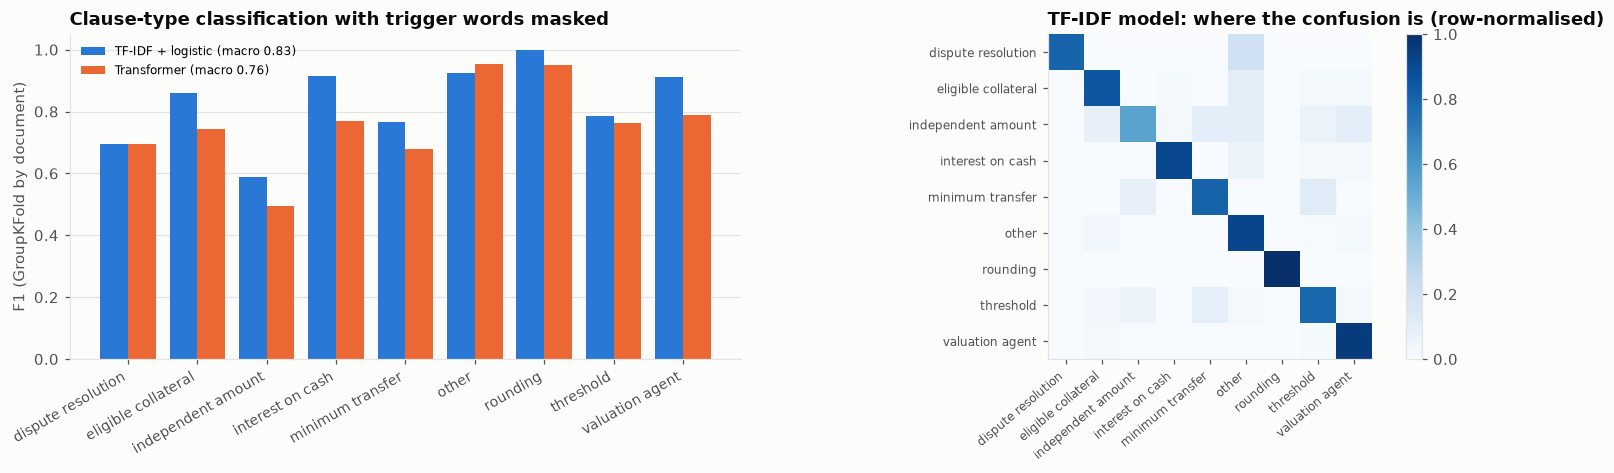

model,TF-IDF + logistic,Transformer (scratch)
field,,
minimum transfer,75.00,25.00
threshold,75.00,75.00


In [9]:
# --- Use on held-out documents: does the top-ranked "threshold" clause contain
# the real election?
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
clf = LogisticRegression(max_iter=2_000, C=5.0, class_weight="balanced").fit(
    vec.fit_transform(dev_cl["masked"]), y
)
model, vocab = train_transformer(dev_cl["masked"].tolist(), y)
hold = clauses_df[
    (clauses_df["set"] == "held-out") & ~clauses_df["doc"].isin(NOT_CSA)
].copy()
p_lr = clf.predict_proba(vec.transform(hold["masked"]))
with torch.no_grad():
    p_tf = torch.softmax(
        model(encode(hold["masked"].tolist(), vocab)), 1
    ).numpy()
rows = []
for field, lab, pat in [
    ("threshold", "threshold", r'"Threshold" means'),
    (
        "minimum transfer",
        "minimum transfer",
        r'"Minimum Transfer Amount"\s*means',
    ),
]:
    k = LABELS.index(lab)
    for doc, g in hold.groupby("doc"):
        for name, p in [
            ("TF-IDF + logistic", p_lr),
            ("Transformer (scratch)", p_tf),
        ]:
            top = g.iloc[
                np.argsort(-p[g.index.map(hold.index.get_loc), k])[:3]
            ]
            rows.append({
                "doc": doc,
                "field": field,
                "model": name,
                "election in top 3 clauses": bool(
                    top["clause"].str.contains(pat).any()
                ),
            })
heldout_rank = (
    pd.DataFrame(rows).pivot_table(
        index="field",
        columns="model",
        values="election in top 3 clauses",
        aggfunc="mean",
    )
    * 100
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
xp = np.arange(len(LABELS))
ax.bar(
    xp - 0.2,
    cv.loc[LABELS, "TF-IDF + logistic"],
    0.4,
    color=PALETTE[0],
    label=(
        "TF-IDF + logistic (macro"
        f" {cv.loc['macro F1', 'TF-IDF + logistic']:.2f})"
    ),
)
ax.bar(
    xp + 0.2,
    cv.loc[LABELS, "Transformer (scratch)"],
    0.4,
    color=PALETTE[1],
    label=(
        "Transformer (macro"
        f" {cv.loc['macro F1', 'Transformer (scratch)']:.2f})"
    ),
)
ax.set_xticks(xp, LABELS, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("F1 (GroupKFold by document)")
ax.set_title("Clause-type classification with trigger words masked")
ax.legend(fontsize=8)
ax.grid(axis="x", visible=False)
ax = axes[1]
cm = pd.crosstab(
    pd.Series([LABELS[i] for i in y], name="weak label"),
    pd.Series([LABELS[i] for i in pred_lr], name="predicted"),
    normalize="index",
)
im = ax.imshow(cm.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(
    range(len(cm.columns)), cm.columns, rotation=40, ha="right", fontsize=8
)
ax.set_yticks(range(len(cm.index)), cm.index, fontsize=8)
ax.set_title("TF-IDF model: where the confusion is (row-normalised)")
ax.grid(False)
plt.colorbar(im, ax=ax)
plt.tight_layout()
save_fig(fig, "01_clause_classifier")
plt.show()
heldout_rank.round(0)

## 7. The inventory in SQL

The extracted terms and their evidence go into DuckDB tables. These are the queries a credit officer runs: threshold structures by party, MTA levels, how many CSAs rely on **rating triggers**, and the review queue of documents where a field could not be extracted.

In [10]:
con = duckdb.connect()
inv_sql = inventory.drop(
    columns=[c for c in inventory.columns if c.endswith("_source")],
    errors="ignore",
)
con.register("csa_inventory", inv_sql)
con.register("csa_evidence", evidence)

structure = con.execute("""
    SELECT COALESCE(threshold_A, 'not extracted') AS structure,
           COUNT(*) FILTER (WHERE TRUE)          AS party_A,
           NULL AS party_B
    FROM csa_inventory WHERE form <> 'not a CSA' GROUP BY 1
""").df()
structure_b = con.execute("""
    SELECT COALESCE(threshold_B, 'not extracted') AS structure, COUNT(*) AS party_B
    FROM csa_inventory WHERE form <> 'not a CSA' GROUP BY 1
""").df()
structure = (
    structure.drop(columns="party_B")
    .merge(structure_b, on="structure", how="outer")
    .fillna(0)
)

kpis = con.execute("""
    SELECT COUNT(*)                                                                    AS csas,
           COUNT(*) FILTER (WHERE form = '2016 VM CSA')                                AS vm_csas,
           COUNT(*) FILTER (WHERE threshold_A = 'contingent' OR threshold_B = 'contingent') AS rating_or_event_triggered,
           COUNT(*) FILTER (WHERE threshold_A = 'fixed amount' OR threshold_B = 'fixed amount') AS with_unsecured_threshold,
           MAX(GREATEST(COALESCE(threshold_A_usd, 0), COALESCE(threshold_B_usd, 0)))  AS largest_threshold_usd,
           MEDIAN(mta_A_usd)                                                           AS median_mta_usd
    FROM csa_inventory WHERE form <> 'not a CSA'
""").df()

review_queue = con.execute("""
    SELECT doc, filer,
           (threshold_A IS NULL)::INT + (threshold_B IS NULL)::INT + (mta_A_usd IS NULL)::INT + (mta_B_usd IS NULL)::INT AS missing_key_fields,
           form
    FROM csa_inventory WHERE form <> 'not a CSA'
    ORDER BY missing_key_fields DESC LIMIT 8
""").df()

audit_example = con.execute("""
    SELECT i.doc, i.threshold_A, e.evidence
    FROM csa_inventory i JOIN csa_evidence e ON e.doc = i.doc AND e.field = 'threshold_A'
    WHERE i.threshold_A = 'contingent' LIMIT 1
""").df()
display(kpis)
display(review_queue)
print("Audit trail example →", audit_example.iloc[0]["evidence"][:300], "…")

,csas,vm_csas,rating_or_event_triggered,with_unsecured_threshold,largest_threshold_usd,median_mta_usd
0,29,3,11,6,"30,000,000.00","100,000.00"


,doc,filer,missing_key_fields,form
0,1380367/000138036706000005/sp4exh105.htm,RAAC Series 2006-SP4 Trust,4,1994 Credit Support Annex (NY law)
1,1048982/000101287003001580/dex121.htm,ARTISAN COMPONENTS INC,4,1994 Credit Support Annex (NY law)
2,2078265/000207826526000184/ex-hxv.htm,Corgi ETF Trust I,2,2016 VM CSA
3,78150/000119312506006137/dex9950.htm,PLDT Inc.,2,1994 Credit Support Annex (NY law)
4,1095007/000119312517254027/d213831dex119.htm,DIVERSIFIED 2000 FUTURES FUND L.P.,2,2016 VM CSA
5,2078265/000207826526000184/ex-hxi.htm,Corgi ETF Trust I,2,2016 VM CSA
6,931301/000101905616001006/ex99_16.htm,FCMI FINANCIAL CORP ET AL,1,1994 Credit Support Annex (NY law)
7,1428525/000110465908025926/a08-11987_1ex4d11.htm,CNH Equipment Trust 2008-A,0,1994 Credit Support Annex (NY law)


Audit trail example → "Threshold" means, with respect to Party A and any Valuation Date, zero if a Collateral Event has occurred and has been continuing (i) for at least 30 Local Business Days if such Collateral Event is attributable to credit ratings of Moody's, (ii) for at least 10 Local Business Days if such Collatera …


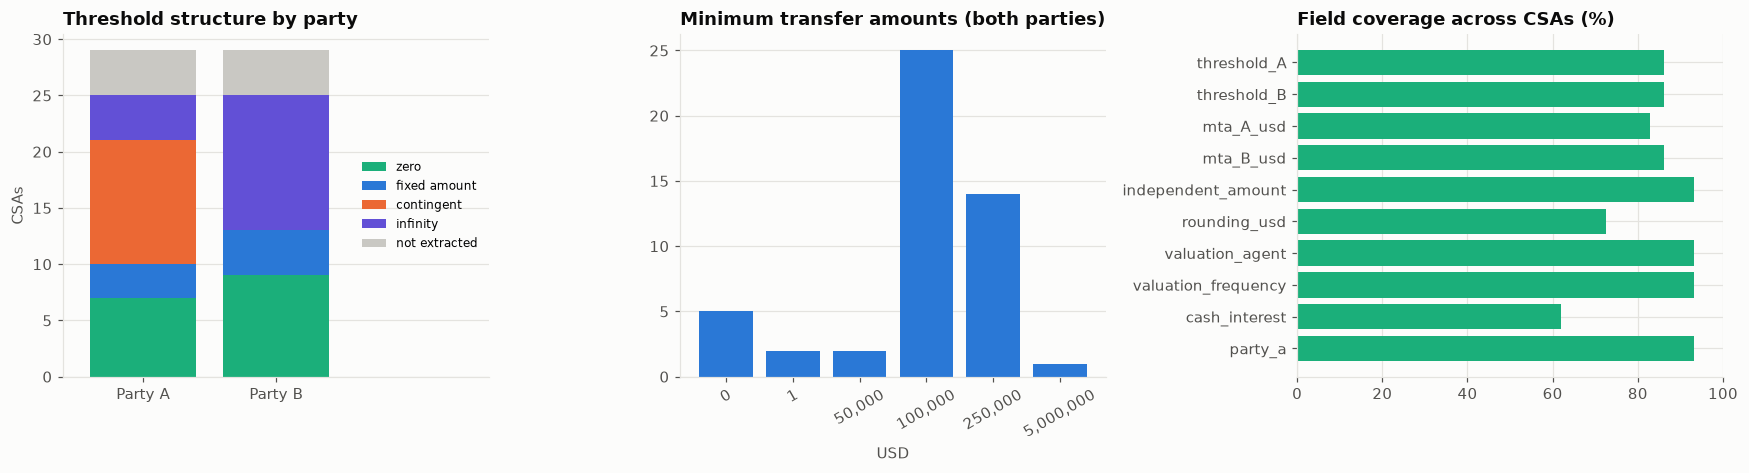

,structure,party_A,party_B
0,contingent,11,0.00
1,fixed amount,3,4.00
2,infinity,4,12.00
3,not extracted,4,4.00
4,zero,7,9.00


In [11]:
# --- Chart 2: the inventory at a glance
csa = inventory[inventory["form"] != "not a CSA"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]
order = ["zero", "fixed amount", "contingent", "infinity", "not extracted"]
st = structure.set_index("structure").reindex(order).fillna(0)
xp = np.arange(2)
bottom = np.zeros(2)
for cat in order:
    vals = st.loc[cat, ["party_A", "party_B"]].to_numpy(dtype=float)
    ax.bar(
        ["Party A", "Party B"],
        vals,
        bottom=bottom,
        color=CAT_COLORS[cat],
        label=cat,
    )
    bottom += vals
ax.set_title("Threshold structure by party")
ax.set_ylabel("CSAs")
ax.set_xlim(-0.6, 2.6)
ax.legend(fontsize=8, loc="center right")
ax.grid(axis="x", visible=False)
ax = axes[1]
mta = pd.concat([csa["mta_A_usd"], csa["mta_B_usd"]]).dropna()
counts = mta.value_counts().sort_index()
ax.bar([f"{v:,.0f}" for v in counts.index], counts.values, color=PALETTE[0])
ax.set_title("Minimum transfer amounts (both parties)")
ax.set_xlabel("USD")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="x", visible=False)
ax = axes[2]
fields = [
    "threshold_A",
    "threshold_B",
    "mta_A_usd",
    "mta_B_usd",
    "independent_amount",
    "rounding_usd",
    "valuation_agent",
    "valuation_frequency",
    "cash_interest",
    "party_a",
]
cov = csa[[f for f in fields if f in csa]].notna().mean().mul(100)
ax.barh(cov.index[::-1], cov.values[::-1], color=PALETTE[2])
ax.set_xlim(0, 100)
ax.set_title("Field coverage across CSAs (%)")
plt.tight_layout()
save_fig(fig, "02_inventory_overview")
plt.show()
inventory.drop(columns=["filer"]).to_csv(
    OUT_DIR / "csa_inventory.csv", index=False
)
evidence.to_csv(OUT_DIR / "csa_evidence.csv", index=False)
check.to_csv(OUT_DIR / "extraction_validation.csv", index=False)
cv.to_csv(OUT_DIR / "clause_classifier_cv.csv")
structure

## 8. Reading the results and limitations

These results come from the run of 19 October 2026 on 30 EDGAR exhibits.

**The document gate works.** 29 of 30 exhibits are recognised as CSAs, and the held-out unit-incentive plan is rejected.

**The rules are near-perfect on the documents they were written on (99%), but get 63% (10 of 16) right on held-out documents.** That gap is the main lesson here. Every held-out error is a drafting pattern that never appeared in development:

- a rating **grid** of thresholds read as a fixed $30mm;
- the Paragraph 12 default for an unspecified MTA (coded for thresholds but not for MTAs);
- an election cut at an internal enumerator ("1. infinity, unless (i) a Ratings Event…");
- a defaulting-party proviso ("Minimum Transfer Amount means zero") taken as the main value.

Rule-based extraction of credit terms should run with a **review queue** and evidence links, and its accuracy should always be quoted on held-out documents.

**The evidence table makes review fast.** Every extracted value carries its source clause, and the SQL review queue sorts documents by missing key fields.

**What the inventory says:**

- 3 of the 29 CSAs are 2016 VM CSAs, where thresholds no longer exist;
- **11 have thresholds that depend on a rating or an event.** This is the 2006–2008 structured-finance pattern in which the bank posts nothing until it is downgraded: wrong-way collateral that arrives exactly when it is needed most;
- 6 allow unsecured thresholds of up to $30mm;
- the median MTA is $100k.

**The clause classifier** learns clause types from context, with the trigger words masked. Macro-F1 is 0.83 for TF-IDF + logistic regression and 0.76 for the from-scratch Transformer, scored by cross-validation grouped by document.

With about 1,400 labelled clauses, n-grams beat a Transformer trained from scratch. On the held-out CSAs, the real threshold election is among the top 3 clauses the classifier flags in 3 of 4 documents.

That makes the classifier useful as a safety net that points the reviewer to the right paragraph, not as a replacement for the rules.

**Limitations**

- EDGAR exhibits are mostly structured-finance and corporate CSAs from 2003–2026, not bank-to-MDB documents. The ISDA language is the same, but the mix of terms (many rating-triggered thresholds) does not represent an MDB's book.
- Thirty documents are enough to build and validate rules, not to measure accuracy precisely: one error on the held-out set moves accuracy by 6 points.
- Rating-grid thresholds (a table of amounts by rating) are recognised as contingent but not parsed into the grid. Eligible-collateral haircut tables are summarised only as the lowest valuation percentage.
- The Transformer is trained from scratch on a few thousand clauses. A pretrained legal model such as LEGAL-BERT, fine-tuned on the same weak labels, is the natural next step where downloads are allowed.

## References

### Finance and regulation

- Basel Committee on Banking Supervision & International Organization of Securities Commissions. (2020). *Margin requirements for non-centrally cleared derivatives*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d499.htm
- Gregory, J. (2020). *The xVA challenge: Counterparty risk, funding, collateral, capital and initial margin* (4th ed.). Wiley. https://doi.org/10.1002/9781119508991
- Chalkidis, I., Androutsopoulos, I., & Michos, A. (2017). Extracting contract elements. In *Proceedings of the 16th International Conference on Artificial Intelligence and Law*. https://doi.org/10.1145/3086512.3086515

### Machine learning and deep learning

- Chalkidis, I., Fergadiotis, M., Malakasiotis, P., Aletras, N., & Androutsopoulos, I. (2020). LEGAL-BERT: The muppets straight out of law school. In *Findings of EMNLP 2020*. https://doi.org/10.18653/v1/2020.findings-emnlp.261
- Hendrycks, D., Burns, C., Chen, A., & Ball, S. (2021). CUAD: An expert-annotated NLP dataset for legal contract review. *arXiv*. https://arxiv.org/abs/2103.06268
- Ratner, A., Bach, S. H., Ehrenberg, H., Fries, J., Wu, S., & Ré, C. (2017). Snorkel: Rapid training data creation with weak supervision. *Proceedings of the VLDB Endowment, 11*(3), 269–282. https://doi.org/10.14778/3157794.3157797
- Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1706.03762
- Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management, 24*(5), 513–523. https://doi.org/10.1016/0306-4573(88)90021-0